In [7]:
# ===== BOOTSTRAP: run first after every Colab start/restart =====
import os, shutil, subprocess
from pathlib import Path
from google.colab import drive, userdata

# 1) Reconnect Google Drive (permanent storage)
drive.mount('/content/drive')

# 2) Load secrets from the Colab Secrets panel into environment variables
SECRETS = ["GITHUB_USERNAME", "GITHUB_TOKEN", "GIT_EMAIL", "DAGSHUB_USERNAME",
           "DAGSHUB_TOKEN", "KAGGLE_API_TOKEN"]
missing = []
for k in SECRETS:
    try:
        os.environ[k] = userdata.get(k)
    except Exception:
        missing.append(k)
print(f"Secrets loaded: {len(SECRETS)-len(missing)}/{len(SECRETS)}  missing: {missing or 'none'}")

# 3) Project paths
PROJECT     = "23L-0951_A2_Ops"
DRIVE       = Path("/content/drive/MyDrive")
PROJECT_DIR = DRIVE / PROJECT              # git repo (code, notebooks, small files)
WORK_DIR    = DRIVE / f"{PROJECT}_work"    # big files kept OUT of git
LOCAL_DATA  = Path("/content/data")        # fast local copy, rebuilt each session
for p in (WORK_DIR, LOCAL_DATA):
    p.mkdir(parents=True, exist_ok=True)
os.environ.update(PROJECT_DIR=str(PROJECT_DIR), WORK_DIR=str(WORK_DIR),
                  LOCAL_DATA=str(LOCAL_DATA))
os.environ["DVC_NO_ANALYTICS"] = "1"

def sh(cmd, cwd=None):
    """Run a shell command and print its output. Returns the exit code."""
    r = subprocess.run(cmd, shell=True, cwd=cwd, text=True, capture_output=True)
    out = (r.stdout + r.stderr).strip()
    if out:
        print(out)
    return r.returncode

# 4) Git settings: one credential helper per website, tokens read from env vars.
#    GitHub gets the GitHub token, DagsHub gets the DagsHub token.
#    Tokens are never saved inside the repo or in remote URLs.
gh_helper = '!f() { echo "username=${GITHUB_USERNAME}"; echo "password=${GITHUB_TOKEN}"; }; f'
dh_helper = '!f() { echo "username=${DAGSHUB_USERNAME}"; echo "password=${DAGSHUB_TOKEN}"; }; f'
subprocess.run(["git", "config", "--global", "--unset-all", "credential.helper"])  # remove old generic helper
for key, val in [("credential.https://github.com.helper", gh_helper),
                 ("credential.https://dagshub.com.helper", dh_helper),
                 ("user.name", "Zayan"),
                 ("user.email", os.environ.get("GIT_EMAIL", "")),
                 ("init.defaultBranch", "main")]:
    subprocess.run(["git", "config", "--global", key, val], check=True)

# 5) Clone the repo into Drive the first time; afterwards just pull updates
if not (PROJECT_DIR / ".git").exists():
    sh(f'git clone https://github.com/{os.environ["GITHUB_USERNAME"]}/{PROJECT}.git "{PROJECT_DIR}"')
if not (PROJECT_DIR / ".git").exists():
    raise SystemExit("Clone failed: check GITHUB_USERNAME / GITHUB_TOKEN / repo name.")
os.chdir(PROJECT_DIR)
sh("rm -f .git/index.lock")      # clears a leftover lock from a dropped session
sh("git pull --ff-only")

# 6) Reinstall pinned packages
if (PROJECT_DIR / "requirements-colab.txt").exists():
    sh("pip install -q -r requirements-colab.txt")

# 7) Helper to save a step: copy notebook into repo, commit, push
def save_step(message, notebook_name=None):
    if notebook_name:
        src = DRIVE / "Colab Notebooks" / notebook_name
        (PROJECT_DIR / "notebooks").mkdir(exist_ok=True)
        if src.exists():
            shutil.copy(src, PROJECT_DIR / "notebooks" / notebook_name)
        else:
            print("Notebook not found:", src)
    sh("git add -A")
    sh(f'git commit -m "{message}"')
    sh("git push origin main")
    sh("git log --oneline -1")

print("Bootstrap done. Working directory:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Secrets loaded: 6/6  missing: none
Already up to date.
Bootstrap done. Working directory: /content/drive/MyDrive/23L-0951_A2_Ops


In [8]:
import zipfile, time, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf, keras, mlflow

# Fast local copy of the images (rebuilt from the zip on Drive each session)
RAW_LOCAL = LOCAL_DATA / "raw"
ZIP_PATH = next((WORK_DIR / "raw_zip").glob("*.zip"))
if not (RAW_LOCAL.exists() and any(RAW_LOCAL.rglob("*.*"))):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RAW_LOCAL)
print("Local images:", sum(1 for p in RAW_LOCAL.rglob("*") if p.is_file()))

# MLflow -> DagsHub, credentials from Colab Secrets via environment variables
os.environ["MLFLOW_TRACKING_URI"]      = f"https://dagshub.com/{os.environ['DAGSHUB_USERNAME']}/{PROJECT}.mlflow"
os.environ["MLFLOW_TRACKING_USERNAME"] = os.environ["DAGSHUB_USERNAME"]
os.environ["MLFLOW_TRACKING_PASSWORD"] = os.environ["DAGSHUB_TOKEN"]
mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])

# Folders for checkpoints/tuner results on Drive (survive disconnects)
CKPT_DIR  = WORK_DIR / "checkpoints"; CKPT_DIR.mkdir(exist_ok=True)
TUNER_DIR = WORK_DIR / "tuner";       TUNER_DIR.mkdir(exist_ok=True)
FIG_DIR   = PROJECT_DIR / "reports" / "figures"

SEED = 42
keras.utils.set_random_seed(SEED)       # seeds Python, NumPy and TensorFlow together
print("TF", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

Local images: 975
TF 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
%%writefile src/data.py
"""
VisionGuard input pipeline (Task 2.1).

decode_and_resize() is shared by training and the Flask app, so both
apply exactly the same preprocessing. Models receive pixels in 0..255
and normalise internally, so serving cannot use the wrong scaling.
"""
from pathlib import Path

import pandas as pd
import tensorflow as tf
import keras

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
CLASS_NAMES = {0: "real", 1: "ai"}

AUG_SETTINGS = {
    "mild":   dict(rotation=0.05, zoom=0.10, contrast=0.10),
    "strong": dict(rotation=0.15, zoom=0.25, contrast=0.25),
}


def decode_and_resize(raw_bytes, img_size=IMG_SIZE):
    """Encoded image bytes -> uint8 tensor (img_size, img_size, 3).

    - decode_image handles JPEG/PNG/GIF/WEBP/BMP; channels=3 converts
      grayscale and drops alpha; expand_animations=False takes a GIF's first frame.
    - resize_with_pad keeps the aspect ratio and fills the rest with black
      (letterboxing) instead of stretching the image.
    """
    img = tf.io.decode_image(raw_bytes, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize_with_pad(img, img_size, img_size, antialias=True)
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)


def load_image(path, img_size=IMG_SIZE):
    return decode_and_resize(tf.io.read_file(path), img_size)


def make_augmenter(strength="mild", seed=42):
    """Random augmentation for TRAINING only. Returns None for 'none'."""
    if strength == "none":
        return None
    s = AUG_SETTINGS[strength]
    return keras.Sequential([
        keras.layers.RandomFlip("horizontal", seed=seed),
        keras.layers.RandomRotation(s["rotation"], fill_mode="constant", seed=seed),
        keras.layers.RandomZoom(s["zoom"], fill_mode="constant", seed=seed),
        keras.layers.RandomContrast(s["contrast"], seed=seed),
    ], name=f"augment_{strength}")


def read_split(split_csv, data_root):
    df = pd.read_csv(split_csv)
    paths = [str(Path(data_root) / p) for p in df["rel_path"]]
    return paths, df["label"].astype("int32").tolist(), df


def make_dataset(split_csv, data_root, training, img_size=IMG_SIZE,
                 batch_size=BATCH_SIZE, augment="mild", seed=42):
    """Split list -> batched, prefetched tf.data.Dataset of (images 0..255 float32, labels)."""
    paths, labels, _ = read_split(split_csv, data_root)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    # 1) read + decode + resize, in parallel
    ds = ds.map(lambda p, y: (load_image(p, img_size), y), num_parallel_calls=AUTOTUNE)
    # 2) cache decoded uint8 images in RAM: decoding happens only once
    ds = ds.cache()
    # 3) shuffle training data only; new order every epoch
    if training:
        ds = ds.shuffle(len(paths), seed=seed, reshuffle_each_iteration=True)
    # 4) batch, then convert to float for the model
    ds = ds.batch(batch_size)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), tf.cast(y, tf.float32)),
                num_parallel_calls=AUTOTUNE)
    # 5) augmentation on training batches only (never on val/test, never inside the saved model)
    aug = make_augmenter(augment, seed) if training else None
    if aug is not None:
        ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=AUTOTUNE)
    # 6) prefetch: prepare the next batch while the GPU trains on the current one
    return ds.prefetch(AUTOTUNE)

Writing src/data.py


In [9]:
import importlib, sys
sys.path.insert(0, str(PROJECT_DIR))
import src.data as data; importlib.reload(data)

SPLITS = PROJECT_DIR / "data" / "splits"
train_ds = data.make_dataset(SPLITS / "train.csv", RAW_LOCAL, training=True)
val_ds   = data.make_dataset(SPLITS / "val.csv",   RAW_LOCAL, training=False)
test_ds  = data.make_dataset(SPLITS / "test.csv",  RAW_LOCAL, training=False)

print("Element spec:", train_ds.element_spec)
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    print(f"{name:5s}: {sum(1 for _ in ds)} batches")

# Show the effect of caching: the 1st pass decodes from disk, the 2nd reads from RAM
for i in (1, 2):
    t = time.time(); n = sum(int(x.shape[0]) for x, _ in train_ds)
    print(f"Pass {i}: {n} images in {time.time()-t:.1f}s")

Element spec: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))
train: 22 batches
val  : 5 batches
test : 5 batches
Pass 1: 681 images in 1.0s
Pass 2: 681 images in 1.0s


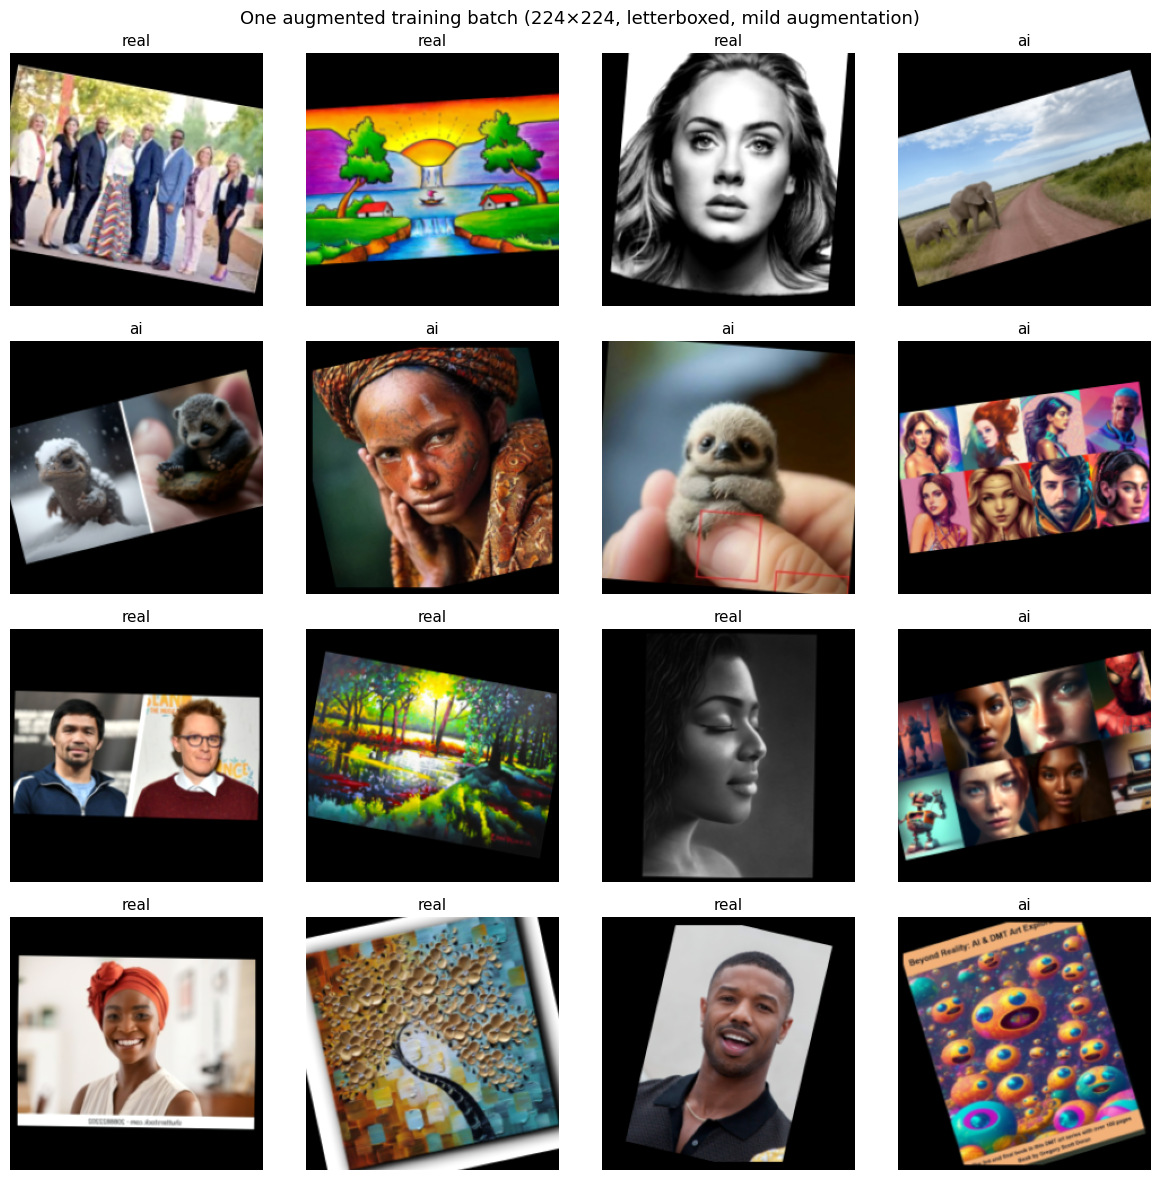

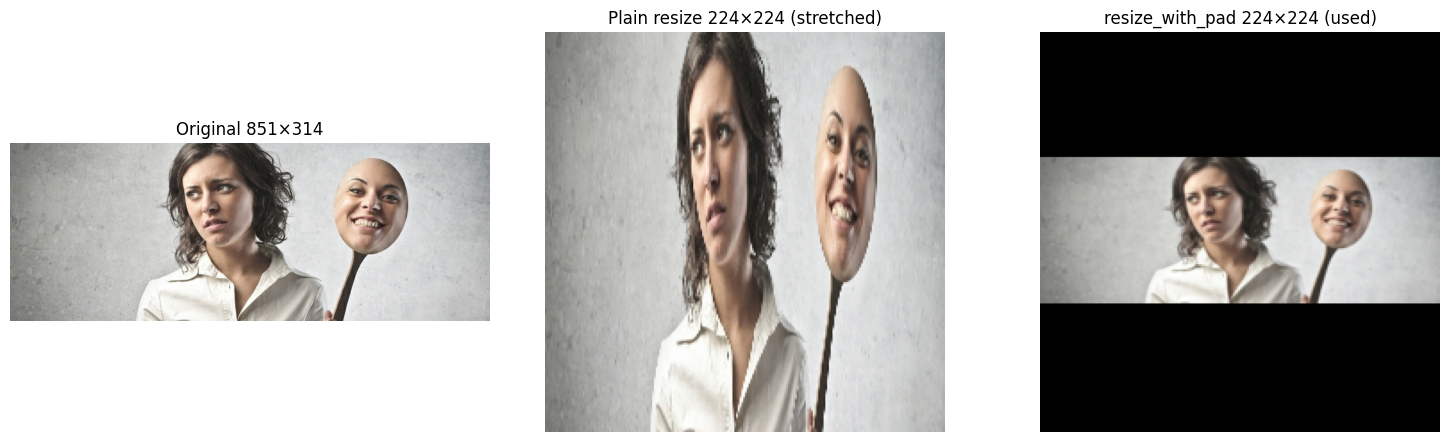

In [5]:
# Figure 1: one augmented training batch
images, labels = next(iter(train_ds))
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for ax, img, y in zip(axes.flat, images[:16], labels[:16]):
    ax.imshow(np.clip(img.numpy() / 255.0, 0, 1))
    ax.set_title(data.CLASS_NAMES[int(y)], fontsize=11)
    ax.axis("off")
fig.suptitle("One augmented training batch (224×224, letterboxed, mild augmentation)", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "pipeline_augmented_batch.png", dpi=110, bbox_inches="tight")
plt.show()

# Figure 2: what happens to aspect ratio (original vs stretch vs letterbox)
from PIL import Image
audit = pd.read_csv("reports/audit/audit_table.csv")
wide = audit[audit.readable].assign(ar=lambda d: d.width / d.height).sort_values("ar").iloc[-5]
raw = tf.io.read_file(str(RAW_LOCAL / wide.rel_path))
orig = tf.io.decode_image(raw, channels=3, expand_animations=False)
stretched = tf.cast(tf.image.resize(orig, (224, 224)), tf.uint8)
padded = data.decode_and_resize(raw)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, im, title in zip(axes, [orig, stretched, padded],
                         [f"Original {int(wide.width)}×{int(wide.height)}",
                          "Plain resize 224×224 (stretched)",
                          "resize_with_pad 224×224 (used)"]):
    ax.imshow(im.numpy()); ax.set_title(title); ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "pipeline_aspect_ratio.png", dpi=110, bbox_inches="tight")
plt.show()

In [6]:
save_step("Step 10: tf.data input pipeline + figures (Task 2.1)", "03_training.ipynb");

[main a44b780] Step 10: tf.data input pipeline + figures (Task 2.1)
 4 files changed, 84 insertions(+)
 create mode 100644 notebooks/03_training.ipynb
 create mode 100644 reports/figures/pipeline_aspect_ratio.png
 create mode 100644 reports/figures/pipeline_augmented_batch.png
 create mode 100644 src/data.py
To https://github.com/bhatti-zayan/23L-0951_A2_Ops.git
   a66cf5d..a44b780  main -> main
a44b780 Step 10: tf.data input pipeline + figures (Task 2.1)


In [10]:
import json, yaml
from mlflow.models import infer_signature
from keras import layers, callbacks

EXPERIMENT = "23L-0951_A2_Ops_visionguard"
mlflow.set_experiment(EXPERIMENT)
RUN_IDS_FILE = PROJECT_DIR / "reports" / "run_ids.json"

def git_info():
    run = lambda c: subprocess.run(c, shell=True, capture_output=True, text=True, cwd=PROJECT_DIR).stdout.strip()
    return run("git rev-parse HEAD"), bool(run("git status --porcelain"))

def dvc_data_version():
    return yaml.safe_load((PROJECT_DIR / "data" / "raw.dvc").read_text())["outs"][0]["md5"]

def base_tags(model_type, logging_mode):
    commit, dirty = git_info()
    gpu = tf.config.list_physical_devices("GPU")
    return {"git_commit": commit, "git_dirty": str(dirty),
            "dvc_data_version": dvc_data_version(), "seed": str(SEED),
            "model_type": model_type, "logging": logging_mode, "student": "23L-0951",
            "gpu": tf.config.experimental.get_device_details(gpu[0]).get("device_name") if gpu else "none"}

class ManualMlflowLogger(keras.callbacks.Callback):
    """Manual logging: after every epoch send all Keras metrics + current LR to MLflow."""
    def on_epoch_end(self, epoch, logs=None):
        logs = {k: float(v) for k, v in (logs or {}).items()}
        logs["lr"] = float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate))
        mlflow.log_metrics(logs, step=epoch + 1)          # step = 1-based epoch number

def make_callbacks(tag, es_patience=8, lr_patience=3):
    return [
        callbacks.EarlyStopping(monitor="val_loss", patience=es_patience,
                                restore_best_weights=True, verbose=1),
        callbacks.ModelCheckpoint(str(CKPT_DIR / f"{tag}_best.keras"), monitor="val_loss",
                                  save_best_only=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=lr_patience,
                                    min_lr=1e-6, verbose=1),
        callbacks.CSVLogger(str(CKPT_DIR / f"{tag}_history.csv")),
    ]

def plot_curves(h, title, filename):
    """Loss + accuracy curves with the best epoch (lowest val_loss) marked."""
    ep = np.arange(1, len(h["loss"]) + 1)
    best = int(np.argmin(h["val_loss"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, key in zip(axes, ["loss", "accuracy"]):
        ax.plot(ep, h[key], "o-", ms=3, label=f"train {key}")
        ax.plot(ep, h[f"val_{key}"], "o-", ms=3, label=f"val {key}")
        ax.axvline(best, color="red", ls="--", label=f"best epoch = {best}")
        ax.set_xlabel("epoch"); ax.set_ylabel(key); ax.legend(); ax.grid(alpha=.3)
    fig.suptitle(title); fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=110, bbox_inches="tight")
    return fig, best

def log_common_artifacts():
    mlflow.log_artifacts(str(PROJECT_DIR / "data" / "splits"), artifact_path="splits")
    mlflow.log_artifact(str(PROJECT_DIR / "reports" / "environment" / "pip-freeze-colab.txt"), "environment")
    mlflow.log_artifact(str(PROJECT_DIR / "requirements-colab.txt"), "environment")

def log_keras_model(model, tag, sample_batch):
    sig = infer_signature(sample_batch.numpy(), model.predict(sample_batch, verbose=0))
    mlflow.keras.log_model(model, name="model", signature=sig)    # MLflow model (Logged Models page)
    path = CKPT_DIR / f"{tag}_final.keras"; model.save(path)
    mlflow.log_artifact(str(path), artifact_path="model_file")    # plain file (Artifacts tab)

def save_run_id(key, run_id):
    ids = json.loads(RUN_IDS_FILE.read_text()) if RUN_IDS_FILE.exists() else {}
    ids[key] = run_id; RUN_IDS_FILE.write_text(json.dumps(ids, indent=2))

METRICS = lambda: [keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc"),
                   keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")]
print("Experiment:", EXPERIMENT, "| DVC data version:", dvc_data_version())

2026/11/06 09:48:34 INFO mlflow.tracking.fluent: Experiment with name '23L-0951_A2_Ops_visionguard' does not exist. Creating a new experiment.


Experiment: 23L-0951_A2_Ops_visionguard | DVC data version: b2cec67839f742df4653f66d4bcbbafb.dir


In [11]:
def build_cnn(img_size=224, filters=(32, 64, 128, 256), dropout=0.5):
    inputs = keras.Input((img_size, img_size, 3), name="image_0_255")
    x = layers.Rescaling(1.0 / 255, name="rescale_0_1")(inputs)
    for i, f in enumerate(filters, start=1):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"conv{i}")(x)
        x = layers.BatchNormalization(name=f"bn{i}")(x)
        x = layers.ReLU(name=f"relu{i}")(x)
        x = layers.MaxPooling2D(2, name=f"pool{i}")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="dropout")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="p_ai")(x)
    return keras.Model(inputs, outputs, name="visionguard_cnn")

keras.utils.set_random_seed(SEED)
cnn = build_cnn()
cnn.summary()

layer_table = pd.DataFrame([{"layer": l.name, "type": type(l).__name__,
                             "output_shape": str(tuple(l.output.shape)),
                             "params": l.count_params()} for l in cnn.layers])
display(layer_table)
layer_table.to_csv(PROJECT_DIR / "reports" / "cnn_layer_table.csv", index=False)
print("Total params:", cnn.count_params())

Model: "visionguard_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_0_255 (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_0_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (ReLU)                    │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_ai (Dense)                    │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 390,113 (1.49 MB)

 Trainable params: 389,153 (1.48 MB)

 Non-trainable params: 960 (3.75 KB)

,layer,type,output_shape,params
0,image_0_255,InputLayer,"(None, 224, 224, 3)",0
1,rescale_0_1,Rescaling,"(None, 224, 224, 3)",0
2,conv1,Conv2D,"(None, 224, 224, 32)",864
3,bn1,BatchNormalization,"(None, 224, 224, 32)",128
4,relu1,ReLU,"(None, 224, 224, 32)",0
5,pool1,MaxPooling2D,"(None, 112, 112, 32)",0
6,conv2,Conv2D,"(None, 112, 112, 64)",18432
7,bn2,BatchNormalization,"(None, 112, 112, 64)",256
8,relu2,ReLU,"(None, 112, 112, 64)",0
9,pool2,MaxPooling2D,"(None, 56, 56, 64)",0


Total params: 390113


Epoch 1/40
22/22 - 32s - 1s/step - accuracy: 0.5609 - auc: 0.5787 - loss: 0.7892 - precision: 0.5919 - recall: 0.6596 - val_accuracy: 0.5479 - val_auc: 0.5866 - val_loss: 0.6826 - val_precision: 0.5564 - val_recall: 0.9136 - learning_rate: 0.0010
Epoch 2/40
22/22 - 2s - 96ms/step - accuracy: 0.5786 - auc: 0.6060 - loss: 0.7454 - precision: 0.6093 - recall: 0.6596 - val_accuracy: 0.5548 - val_auc: 0.6129 - val_loss: 0.6834 - val_precision: 0.5548 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/40
22/22 - 2s - 96ms/step - accuracy: 0.6256 - auc: 0.6555 - loss: 0.6864 - precision: 0.6547 - recall: 0.6809 - val_accuracy: 0.5479 - val_auc: 0.5953 - val_loss: 0.6828 - val_precision: 0.5540 - val_recall: 0.9506 - learning_rate: 0.0010
Epoch 4/40

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
22/22 - 2s - 95ms/step - accuracy: 0.6300 - auc: 0.6722 - loss: 0.6737 - precision: 0.6498 - recall: 0.7154 - val_accuracy: 0.5548 - val_auc: 0.6226 - val_loss: 0.6902 -

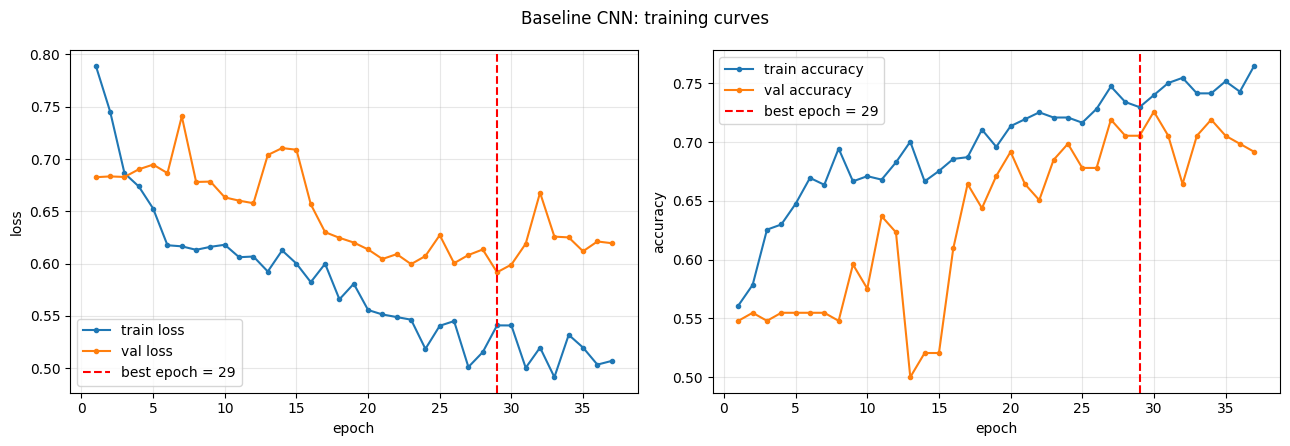


Best epoch: 29 | best val_loss: 0.5917 | run_id: 2e262f2bf3a54cbc889058ee0fa2e0b8
🏃 View run cnn_baseline_manual at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1/runs/2e262f2bf3a54cbc889058ee0fa2e0b8
🧪 View experiment at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1


In [12]:
TAG, EPOCHS, LR = "cnn_baseline", 40, 1e-3
keras.utils.set_random_seed(SEED)
cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(LR), loss="binary_crossentropy", metrics=METRICS())

params = {"model": "baseline_cnn", "img_size": 224, "batch_size": 32, "learning_rate": LR,
          "max_epochs": EPOCHS, "optimizer": "adam", "loss": "binary_crossentropy",
          "augmentation": "mild", "dropout": 0.5, "filters": "32-64-128-256",
          "early_stopping_patience": 8, "reduce_lr_patience": 3, "resize": "pad_224"}

with mlflow.start_run(run_name="cnn_baseline_manual") as run:
    mlflow.set_tags(base_tags("baseline_cnn", "manual_callback"))
    mlflow.log_params(params)
    hist = cnn.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=2,
                   callbacks=make_callbacks(TAG) + [ManualMlflowLogger()])

    fig, best = plot_curves(hist.history, "Baseline CNN: training curves", "cnn_baseline_curves.png")
    mlflow.log_figure(fig, "curves/cnn_baseline_curves.png"); plt.show()
    mlflow.log_metrics({"best_epoch": best, "best_val_loss": float(min(hist.history["val_loss"])),
                        "epochs_trained": len(hist.history["loss"])})
    log_common_artifacts()
    sample, _ = next(iter(val_ds))
    log_keras_model(cnn, TAG, sample[:4])
    save_run_id(TAG, run.info.run_id)
    print(f"\nBest epoch: {best} | best val_loss: {min(hist.history['val_loss']):.4f} | run_id: {run.info.run_id}")